Companion to the essay *When generated scenarios miss the critical corner* on the website. All data here are synthetic and generated in this notebook, and every result is **Illustrative (synthetic)**. It uses no recorded or licensed driving data, and runs on a laptop CPU in about a minute. Seeds are fixed. Package versions are in [requirements.txt](requirements.txt).

Each section has a short explanation, code, a figure, and a *Try this* cell that changes one parameter.

## 1. Generate the data

Two generators of cut-in events, four parameters each: ego speed, gap, closing speed Δv and lateral speed. **G1** has no joint tail. **G2** adds an 8 % aggressive component in which tight gaps come with high closing speed. An event is **critical** if the time to collision at lane crossing is below 2 s.

In [1]:
#| code-fold: true
import json, os, time
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize, stats
import pyvinecopulib as pv
import torch
from torch import nn

torch.set_num_threads(2)
T0 = time.time()
BLUE, ORANGE, GREY, INK = '#2a78d6', '#eb6834', '#c3cad3', '#0f2a4a'


def stamp(fig):
    fig.text(0.995, 0.005, 'Illustrative (synthetic)', ha='right', va='bottom', fontsize=8, color='#6b7686')


PARAMS = ["v_ego", "gap", "dv", "v_lat"]


LANE_W = 3.5          # m


TTC_CRIT = 2.0        # s


A_MAX = 8.0           # m/s^2: required deceleration above this is beyond a passenger car's braking


V_LAT_MAX = 3.0       # m/s


def derived(X):
    """X (n x 4, PARAMS order) -> dict of T_lc, gap_sw, ttc_sw (inf if not closing), drac_sw, v_cut."""
    X = np.atleast_2d(X)
    v, g, dv, vl = X.T
    t_lc = LANE_W / np.maximum(vl, 1e-6)
    g_sw = g - dv * t_lc / 2
    closing = dv > 0
    with np.errstate(divide="ignore", invalid="ignore"):
        ttc = np.where(closing & (g_sw > 0), g_sw / dv, np.inf)
        drac = np.where(closing & (g_sw > 0), dv ** 2 / (2 * g_sw), 0.0)
    return dict(t_lc=t_lc, gap_sw=g_sw, ttc_sw=ttc, drac_sw=drac, v_cut=v - dv)


def validity(X):
    """Physical-validity rules per sample -> dict rule -> boolean array (True = rule satisfied), plus 'all'."""
    X = np.atleast_2d(X)
    v, g, dv, vl = X.T
    d = derived(X)
    rules = {
        "gap > 0": g > 0,
        "0 < v_ego <= 45 m/s": (v > 0) & (v <= 45),
        "v_cutter > 0": d["v_cut"] > 0,
        "0 < v_lat <= 3 m/s": (vl > 0) & (vl <= V_LAT_MAX),
        "gap at lane crossing > 0": d["gap_sw"] > 0,
        "required decel <= 8 m/s^2": d["drac_sw"] <= A_MAX,
    }
    rules["all"] = np.logical_and.reduce(list(rules.values()))
    return rules


def critical(X):
    return derived(X)["ttc_sw"] < TTC_CRIT


def generate_events(n=400, seed=2026):
    """n physically valid cut-ins with correlated parameters (rejection sampling; seeded)."""
    rng = np.random.default_rng(seed)
    out = []
    while len(out) < n:
        m = 4 * n
        v = 12.0 + 30.0 * rng.beta(5, 4, m)                                   # 12..42 m/s, mode ~ 29
        dv = rng.normal(1.5 + 0.15 * (v - 28.0), 3.0)                         # faster ego -> larger closing
        log_tau = rng.normal(np.log(0.7) + 0.05 * dv, 0.4)                    # larger closing -> larger accepted time gap
        gap = v * np.exp(log_tau)
        v_lat = np.exp(rng.normal(np.log(0.9) - 0.4 * (log_tau - np.log(0.7)), 0.2))   # tight gaps -> brisk lane change
        X = np.c_[v, gap, dv, v_lat]
        out += list(X[validity(X)["all"]])
    return np.asarray(out[:n])


def generate_events_tail(n=400, seed=2026, share=0.08):
    """generator G2: G1 plus a tail component in which tight gaps come with high closing speed."""
    rng = np.random.default_rng(seed)
    out = []
    while len(out) < n:
        m = 4 * n
        v = 12.0 + 30.0 * rng.beta(5, 4, m)
        agg = rng.random(m) < share
        dv = np.where(agg, rng.normal(6.5, 1.0, m), rng.normal(1.5 + 0.15 * (v - 28.0), 3.0, m))
        log_tau = np.where(agg, np.log(0.38) - 0.08 * (dv - 6.5) + rng.normal(0, 0.12, m),
                           rng.normal(np.log(0.7) + 0.05 * dv, 0.4, m))
        gap = v * np.exp(log_tau)
        v_lat = np.where(agg, np.exp(rng.normal(np.log(1.7), 0.15, m)),
                         np.exp(rng.normal(np.log(0.9) - 0.4 * (log_tau - np.log(0.7)), 0.2, m)))
        X = np.c_[v, gap, dv, v_lat]
        out += list(X[validity(X)["all"]])
    return np.asarray(out[:n])


def tail_dependence(X, q=0.10):
    """Empirical tail dependence for the dangerous corner: P(gap/v_ego in its lowest q | dv in its highest q),
    ranks within X. Independent variables give about q; a Gaussian copula with this rank correlation gives far less."""
    g = stats.rankdata(X[:, 1] / X[:, 0]) / len(X)
    d = stats.rankdata(X[:, 2]) / len(X)
    hi = d > 1 - q
    return float((g[hi] <= q).mean()) if hi.any() else float("nan")


def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return float(c - h), float(c + h)


def reject_invalid(S):
    """the hand-over filter. Keep only physically valid samples; returns (accepted samples, acceptance rate).
    The accepted samples follow the fitted model truncated to the valid region (density / acceptance rate)."""
    ok = validity(S)["all"]
    return S[ok], float(ok.mean())

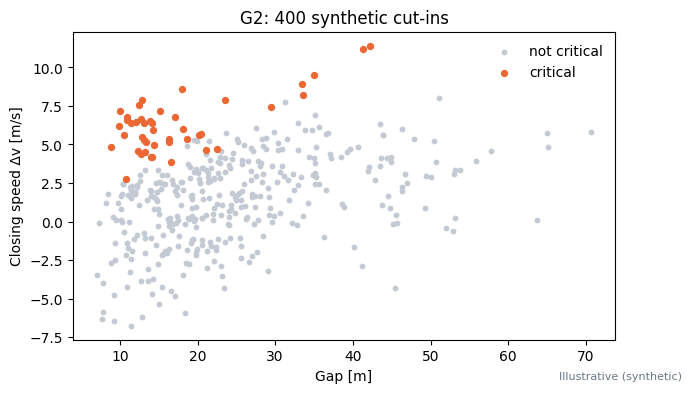

Truth from 200,000 draws: critical share 0.1224, λ(0.10) 0.218


In [2]:
N_EVENTS, SEED, N_SAMPLES, SAMPLE_SEED, N_HELD_OUT = 400, 2026, 10_000, 7, 160


def split(X):
    p = np.random.default_rng(SEED + 1).permutation(len(X))
    n_tr = int(0.6 * len(X))
    return X[p[:n_tr]], X[p[n_tr:]]


G1_tr, G1_ho = split(generate_events(N_EVENTS, SEED))
G2_tr, G2_ho = split(generate_events_tail(N_EVENTS, SEED))
truth = generate_events_tail(200_000, 7)
TRUTH_SHARE, TRUTH_LAM = float(critical(truth).mean()), tail_dependence(truth, 0.10)
results = {"truth": {"critical_share": TRUTH_SHARE, "lambda": TRUTH_LAM}}

ev = np.r_[G2_tr, G2_ho]
c = critical(ev)
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(ev[~c, 1], ev[~c, 2], s=10, color=GREY, label="not critical")
ax.scatter(ev[c, 1], ev[c, 2], s=18, color=ORANGE, label="critical")
ax.set(xlabel="Gap [m]", ylabel="Closing speed Δv [m/s]", title="G2: 400 synthetic cut-ins")
ax.legend(frameon=False); stamp(fig); plt.show()
print(f"Truth from 200,000 draws: critical share {TRUTH_SHARE:.4f}, λ(0.10) {TRUTH_LAM:.3f}")

**Try this.** Change the share of aggressive cut-ins and see how much more λ moves than the critical share.

In [3]:
share = 0.16   # try 0.0, 0.04, 0.16
x = generate_events_tail(100_000, 7, share=share)
print(f"share {share:.2f}: λ(0.10) {tail_dependence(x, 0.10):.3f}, critical share {critical(x).mean():.4f}")

share 0.16: λ(0.10) 0.264, critical share 0.1740


## 2. Fit each model family

Nine models, in the essay's order, all on the same 240 training events. Every model with a copula uses the same one-dimensional KDE marginals, so only the dependence differs. The conditional-extremes threshold is fixed at the top 10 % of closing speed, and the flow's size (4 couplings, width 16) is the one chosen on internal validation.

In [4]:
#| code-fold: true
class _Marginal:
    """1-D Gaussian KDE (Scott's rule) with an analytic CDF and a grid-based inverse CDF."""

    def __init__(self, x):
        self.k = stats.gaussian_kde(x)
        self.x = np.asarray(x, float)
        self.h = float(np.sqrt(self.k.covariance[0, 0]))
        self.grid = np.linspace(self.x.min() - 6 * self.h, self.x.max() + 6 * self.h, 4001)
        self.cdf_grid = self.cdf(self.grid)

    def logpdf(self, v):
        return np.log(np.maximum(self.k(v), 1e-300))

    def cdf(self, v):
        v = np.asarray(v, float)
        return stats.norm.cdf((v[:, None] - self.x[None, :]) / self.h).mean(1)

    def ppf(self, u):
        return np.interp(u, self.cdf_grid, self.grid)

    def sample(self, n, rng):
        return self.k.resample(n, seed=rng)[0]


class Independent:
    """Product of 1-D KDE marginals: the 'independent ranges' baseline with data-fitted marginals."""
    name = "independent marginals (1-D KDE)"

    def fit(self, X):
        self.m = [_Marginal(X[:, j]) for j in range(X.shape[1])]
        return self

    def logpdf(self, X):
        return sum(m.logpdf(X[:, j]) for j, m in enumerate(self.m))

    def sample(self, n, seed):
        rng = np.random.default_rng(seed)
        return np.c_[tuple(m.sample(n, rng) for m in self.m)]

    def info(self):
        return dict(bandwidths=[m.h for m in self.m])


class KDE:
    """Multivariate Gaussian KDE on standardised parameters (Scott's rule, full covariance)."""
    name = "multivariate KDE"

    def fit(self, X):
        self.mu, self.sd = X.mean(0), X.std(0)
        self.k = stats.gaussian_kde(((X - self.mu) / self.sd).T)
        return self

    def logpdf(self, X):
        return self.k.logpdf(((X - self.mu) / self.sd).T) - np.log(self.sd).sum()

    def sample(self, n, seed):
        return self.k.resample(n, seed=np.random.default_rng(seed)).T * self.sd + self.mu

    def info(self):
        return dict(scott_factor=float(self.k.factor))


class GaussianCopula:
    """Gaussian copula on normal scores of 1-D KDE marginals (the same marginals as Independent)."""
    name = "Gaussian copula + KDE marginals"

    def fit(self, X):
        self.m = [_Marginal(X[:, j]) for j in range(X.shape[1])]
        Z = self.to_z(X)
        self.R = np.corrcoef(Z.T)
        self.Ri = np.linalg.inv(self.R)
        self.logdet = float(np.linalg.slogdet(self.R)[1])
        return self

    def to_z(self, X):
        U = np.c_[tuple(m.cdf(X[:, j]) for j, m in enumerate(self.m))]
        return stats.norm.ppf(np.clip(U, 1e-9, 1 - 1e-9))

    def from_z(self, Z):
        U = stats.norm.cdf(Z)
        return np.c_[tuple(m.ppf(U[:, j]) for j, m in enumerate(self.m))]

    def log_copula(self, Z):
        return -0.5 * self.logdet - 0.5 * np.einsum("ij,jk,ik->i", Z, self.Ri - np.eye(len(self.R)), Z)

    def logpdf(self, X):
        return sum(m.logpdf(X[:, j]) for j, m in enumerate(self.m)) + self.log_copula(self.to_z(X))

    def sample_z(self, n, seed, mean=None):
        rng = np.random.default_rng(seed)
        return rng.multivariate_normal(np.zeros(len(self.R)) if mean is None else mean, self.R, size=n)

    def sample(self, n, seed):
        return self.from_z(self.sample_z(n, seed))

    def info(self):
        return dict(bandwidths=[m.h for m in self.m], R=np.round(self.R, 3).tolist())


class TCopula(GaussianCopula):
    """Student-t copula on the same 1-D KDE marginals: R from Kendall's tau (R_ij = sin(pi tau_ij / 2)), degrees of
    freedom nu by maximum likelihood over a grid on the training data. Symmetric tail dependence for finite nu."""
    name = "t copula + KDE marginals"
    NU_GRID = (2, 3, 4, 6, 8, 12, 20, 30, 50)

    def fit(self, X):
        self.m = [_Marginal(X[:, j]) for j in range(X.shape[1])]
        d = X.shape[1]
        R = np.eye(d)
        for i in range(d):
            for j in range(i + 1, d):
                R[i, j] = R[j, i] = np.sin(np.pi * stats.kendalltau(X[:, i], X[:, j]).statistic / 2)
        w, V = np.linalg.eigh(R)                                    # keep R positive definite
        R = V @ np.diag(np.maximum(w, 1e-6)) @ V.T
        dd = np.sqrt(np.diag(R))
        self.R = R / np.outer(dd, dd)
        self.Ri = np.linalg.inv(self.R)
        self.logdet = float(np.linalg.slogdet(self.R)[1])
        U = np.clip(np.c_[tuple(m.cdf(X[:, j]) for j, m in enumerate(self.m))], 1e-9, 1 - 1e-9)
        self.ll_by_nu = {nu: float(self._log_c(U, nu).sum()) for nu in self.NU_GRID}
        self.nu = max(self.ll_by_nu, key=self.ll_by_nu.get)
        return self

    def _log_c(self, U, nu):
        d = U.shape[1]
        T = stats.t.ppf(U, nu)
        q = np.einsum("ij,jk,ik->i", T, self.Ri, T)
        from scipy.special import gammaln
        log_mvt = (gammaln((nu + d) / 2) - gammaln(nu / 2) - d / 2 * np.log(nu * np.pi) - 0.5 * self.logdet
                   - (nu + d) / 2 * np.log1p(q / nu))
        return log_mvt - stats.t.logpdf(T, nu).sum(1)

    def logpdf(self, X):
        U = np.clip(np.c_[tuple(m.cdf(X[:, j]) for j, m in enumerate(self.m))], 1e-9, 1 - 1e-9)
        return sum(m.logpdf(X[:, j]) for j, m in enumerate(self.m)) + self._log_c(U, self.nu)

    def sample(self, n, seed):
        rng = np.random.default_rng(seed)
        Z = rng.multivariate_normal(np.zeros(len(self.R)), self.R, size=n)
        W = rng.chisquare(self.nu, n) / self.nu
        U = stats.t.cdf(Z / np.sqrt(W)[:, None], self.nu)
        return np.c_[tuple(m.ppf(U[:, j]) for j, m in enumerate(self.m))]

    def info(self):
        return dict(bandwidths=[m.h for m in self.m], R=np.round(self.R, 3).tolist(), nu=self.nu,
                    train_copula_loglik_by_nu={str(k): round(v, 2) for k, v in self.ll_by_nu.items()})


class ClaytonPair(GaussianCopula):
    """Pair-copula construction: (gap, dv) by a Clayton copula rotated to the critical corner, i.e. Clayton on
    (u_gap, 1 - u_dv) whose lower tail is small gap x high dv; (v_ego, v_lat) given (gap, dv) by the Gaussian copula's
    conditional c4(u)/c2(u_gap, u_dv). Valid density; theta by maximum likelihood on the training data."""
    name = "rotated Clayton (gap x dv) + Gaussian rest"

    @staticmethod
    def _log_clayton(a, b, th):
        return (np.log1p(th) - (th + 1) * (np.log(a) + np.log(b))
                - (2 + 1 / th) * np.log(a ** -th + b ** -th - 1))

    def fit(self, X):
        super().fit(X)
        U = np.clip(np.c_[tuple(m.cdf(X[:, j]) for j, m in enumerate(self.m))], 1e-9, 1 - 1e-9)
        a, b = U[:, 1], 1 - U[:, 2]
        grid = np.exp(np.linspace(np.log(1e-3), np.log(20), 200))
        ll = [self._log_clayton(a, b, t).sum() for t in grid]
        self.theta = float(grid[int(np.argmax(ll))])
        self.R2 = self.R[np.ix_([1, 2], [1, 2])]
        return self

    def logpdf(self, X):
        U = np.clip(np.c_[tuple(m.cdf(X[:, j]) for j, m in enumerate(self.m))], 1e-9, 1 - 1e-9)
        Z = stats.norm.ppf(U)
        Z2 = Z[:, [1, 2]]
        R2i = np.linalg.inv(self.R2)
        log_c2 = -0.5 * np.linalg.slogdet(self.R2)[1] - 0.5 * np.einsum("ij,jk,ik->i", Z2, R2i - np.eye(2), Z2)
        return (sum(m.logpdf(X[:, j]) for j, m in enumerate(self.m)) + self.log_copula(Z) - log_c2
                + self._log_clayton(U[:, 1], 1 - U[:, 2], self.theta))

    def sample(self, n, seed):
        rng = np.random.default_rng(seed)
        th = self.theta
        a = rng.random(n)                                       # Clayton by conditional inversion
        w = rng.random(n)
        b = (a ** -th * (w ** (-th / (1 + th)) - 1) + 1) ** (-1 / th)
        ug, udv = np.clip(a, 1e-9, 1 - 1e-9), np.clip(1 - b, 1e-9, 1 - 1e-9)
        z2 = np.c_[stats.norm.ppf(ug), stats.norm.ppf(udv)]
        o, k = [0, 3], [1, 2]                                   # Gaussian conditional of (v_ego, v_lat) given (gap, dv)
        S_ok = self.R[np.ix_(o, k)]
        A = S_ok @ np.linalg.inv(self.R2)
        cov = self.R[np.ix_(o, o)] - A @ S_ok.T
        zo = z2 @ A.T + rng.multivariate_normal(np.zeros(2), cov, size=n)
        Z = np.c_[zo[:, 0], z2[:, 0], z2[:, 1], zo[:, 1]]
        return self.from_z(Z)

    def info(self):
        return dict(theta=self.theta, lower_tail_dependence=2 ** (-1 / self.theta))


class GMMScores(GaussianCopula):
    """GMCM-style: a K-component Gaussian mixture (EM, scikit-learn, seeded) on the normal scores of the 1-D KDE
    marginals; density g(z) * prod f_i(x_i) / prod phi(z_i) (change of variables, valid). Not the full GMCM estimator
    of Reichenbaecher et al. (there the mixture's own marginals define the scores); an approximation."""
    name = "Gaussian mixture on normal scores (GMCM-style, two components)"

    def fit(self, X, k=2):
        from sklearn.mixture import GaussianMixture
        self.m = [_Marginal(X[:, j]) for j in range(X.shape[1])]
        Z = self.to_z(X)
        self.g = GaussianMixture(k, covariance_type="full", random_state=0, n_init=5).fit(Z)
        self.R = np.corrcoef(Z.T)
        return self

    def logpdf(self, X):
        Z = self.to_z(X)
        return (sum(m.logpdf(X[:, j]) for j, m in enumerate(self.m)) + self.g.score_samples(Z)
                - stats.norm.logpdf(Z).sum(1))

    def sample(self, n, seed):
        self.g.random_state = seed
        Z, _ = self.g.sample(n)
        return self.from_z(Z[np.random.default_rng(seed).permutation(n)])

    def info(self):
        return dict(weights=np.round(self.g.weights_, 3).tolist(), means=np.round(self.g.means_, 2).tolist())

In [5]:
#| code-fold: true
FAMILIES = [pv.BicopFamily.indep, pv.BicopFamily.gaussian, pv.BicopFamily.student, pv.BicopFamily.clayton, pv.BicopFamily.gumbel,
            pv.BicopFamily.frank, pv.BicopFamily.joe, pv.BicopFamily.bb1, pv.BicopFamily.bb6, pv.BicopFamily.bb7, pv.BicopFamily.bb8]


class Vine:
    """Vine copula on the same KDE marginals; pair families chosen by AIC, rotations included."""

    def fit(self, X):
        self.m = [_Marginal(X[:, j]) for j in range(X.shape[1])]
        ctl = pv.FitControlsVinecop(family_set=FAMILIES, selection_criterion="aic", parametric_method="mle", num_threads=1, show_trace=False)
        self.v = pv.Vinecop.from_data(self.u(X), controls=ctl)
        return self

    def u(self, X):
        return np.clip(np.c_[tuple(m.cdf(X[:, j]) for j, m in enumerate(self.m))], 1e-9, 1 - 1e-9)

    def logpdf(self, X):
        return sum(m.logpdf(X[:, j]) for j, m in enumerate(self.m)) + np.log(np.maximum(self.v.pdf(self.u(X)), 1e-300))

    def sample(self, n, seed):
        U = self.v.simulate(n, seeds=[seed])
        return np.c_[tuple(m.ppf(U[:, j]) for j, m in enumerate(self.m))]


DV, OTHERS = 2, [0, 1, 3]


def to_lap(u):
    u = np.clip(u, 1e-9, 1 - 1e-9)
    return np.where(u < 0.5, np.log(2 * u), -np.log(2 * (1 - u)))


def from_lap(y):
    return np.where(y < 0, 0.5 * np.exp(y), 1 - 0.5 * np.exp(-y))


class HT(GaussianCopula):
    def __init__(self, q=0.90):
        self.q = q
        self.name = f"conditional extremes on high dv (q = {q:.2f}), Gaussian copula below"

    def lap(self, X):
        return np.c_[tuple(to_lap(m.cdf(X[:, j])) for j, m in enumerate(self.m))]

    def fit(self, X):
        super().fit(X)
        self.zq = stats.norm.ppf(self.q)
        L = self.lap(X)
        self.x0 = to_lap(np.array([self.q]))[0]
        hi = L[:, DV] > self.x0
        x, Y = L[hi, DV], L[hi][:, OTHERS]
        self.n_exceed = int(hi.sum())
        self.a, self.b, Z = [], [], []
        for j in range(3):
            y = Y[:, j]

            def nll(t):
                a, b, mu, ls = t
                s = np.exp(ls)
                xb = x ** b
                return np.sum(np.log(s * xb) + 0.5 * ((y - a * x - mu * xb) / (s * xb)) ** 2)

            best = None
            for a0 in (-0.6, 0.0, 0.6):
                o = optimize.minimize(nll, [a0, 0.2, 0.0, 0.0], method="L-BFGS-B", bounds=[(-1, 1), (0, 0.99), (-10, 10), (-5, 5)])
                if best is None or o.fun < best.fun:
                    best = o
            self.a.append(best.x[0])
            self.b.append(best.x[1])
            Z.append((y - best.x[0] * x) / x ** best.x[1])
        self.a, self.b = np.array(self.a), np.array(self.b)
        self.kz = stats.gaussian_kde(np.array(Z))
        return self

    def logpdf(self, X):
        out = super().logpdf(X)
        L = self.lap(X)
        hi = L[:, DV] > self.x0
        if hi.any():
            x, Y, Xh = L[hi, DV], L[hi][:, OTHERS], X[hi]
            Z = (Y - self.a[None, :] * x[:, None]) / x[:, None] ** self.b[None, :]
            lp = self.m[DV].logpdf(Xh[:, DV]) + self.kz.logpdf(Z.T) - (self.b.sum() * np.log(x))
            for k, j in enumerate(OTHERS):
                lp += self.m[j].logpdf(Xh[:, j]) - (-np.log(2) - np.abs(Y[:, k]))
            out = out.copy()
            out[hi] = lp
        return out

    def sample(self, n, seed):
        rng = np.random.default_rng(seed)
        n_hi = rng.binomial(n, 1 - self.q)
        Zb = rng.multivariate_normal(np.zeros(4), self.R, size=int((n - n_hi) / self.q * 1.3) + 1000)
        Zb = Zb[Zb[:, DV] <= self.zq][: n - n_hi]
        B = self.from_z(Zb)
        x = to_lap(rng.uniform(self.q, 1, n_hi))
        z = self.kz.resample(n_hi, seed=rng).T
        y = self.a[None, :] * x[:, None] + x[:, None] ** self.b[None, :] * z
        U = np.zeros((n_hi, 4))
        U[:, DV] = from_lap(x)
        for k, j in enumerate(OTHERS):
            U[:, j] = from_lap(y[:, k])
        T = np.c_[tuple(m.ppf(U[:, j]) for j, m in enumerate(self.m))]
        S = np.r_[B, T]
        return S[rng.permutation(len(S))]

    def info(self):
        return dict(q=self.q, exceedances=self.n_exceed, a=dict(zip([PARAMS[j] for j in OTHERS], np.round(self.a, 3).tolist())),
                    b=dict(zip([PARAMS[j] for j in OTHERS], np.round(self.b, 3).tolist())))

In [6]:
#| code-fold: true
D, EPOCHS, PATIENCE = 4, 4000, 400


class Coupling(nn.Module):
    def __init__(self, mask, width):
        super().__init__()
        self.register_buffer("mask", mask)
        self.net = nn.Sequential(nn.Linear(D, width), nn.ReLU(), nn.Linear(width, width), nn.ReLU(), nn.Linear(width, 2 * D))
        self.scale = nn.Parameter(torch.tensor(0.5))

    def params(self, x):
        s, t = self.net(x * self.mask).chunk(2, 1)
        return torch.tanh(s) * self.scale * (1 - self.mask), t * (1 - self.mask)

    def inverse(self, x):   # data -> base
        s, t = self.params(x)
        return x * self.mask + (1 - self.mask) * (x - t) * torch.exp(-s), -s.sum(1)

    def forward(self, z):   # base -> data
        s, t = self.params(z)
        return z * self.mask + (1 - self.mask) * (z * torch.exp(s) + t)


class Flow:
    name = "normalizing flow (RealNVP, Gaussian base)"

    def __init__(self, seed, cfg):
        self.seed, (self.layers, self.width, self.wd) = seed, cfg

    def fit(self, X):
        torch.manual_seed(self.seed)
        self.mu, self.sd = X.mean(0), X.std(0)
        T = torch.tensor((X - self.mu) / self.sd, dtype=torch.float32)
        p = np.random.default_rng(self.seed).permutation(len(T))
        tr, va = T[p[:200]], T[p[200:]]
        masks = [torch.tensor([(i + k) % 2 for i in range(D)], dtype=torch.float32) for k in range(self.layers)]
        self.f = nn.ModuleList(Coupling(m, self.width) for m in masks)
        opt = torch.optim.Adam(self.f.parameters(), lr=1e-3, weight_decay=self.wd)
        best, best_state, wait = -np.inf, None, 0
        for ep in range(EPOCHS):
            opt.zero_grad()
            loss = -self.logp(tr).mean()
            loss.backward()
            nn.utils.clip_grad_norm_(self.f.parameters(), 5.0)
            opt.step()
            with torch.no_grad():
                v = self.logp(va).mean().item()
            if v > best:
                best, best_state, wait = v, {k: x.clone() for k, x in self.f.state_dict().items()}, 0
            else:
                wait += 1
                if wait > PATIENCE:
                    break
        self.f.load_state_dict(best_state)
        self.epochs, self.val = ep + 1, best
        return self

    def logp(self, x):
        ld = 0
        for c in reversed(self.f):
            x, l = c.inverse(x)
            ld = ld + l
        return -0.5 * (x ** 2).sum(1) - 0.5 * D * np.log(2 * np.pi) + ld

    def logpdf(self, X):
        with torch.no_grad():
            T = torch.tensor((X - self.mu) / self.sd, dtype=torch.float32)
            return self.logp(T).numpy().astype(float) - np.log(self.sd).sum()

    def sample(self, n, seed):
        g = torch.Generator().manual_seed(seed)
        with torch.no_grad():
            z = torch.randn(n, D, generator=g)
            for c in self.f:
                z = c(z)
        return z.numpy().astype(float) * self.sd + self.mu

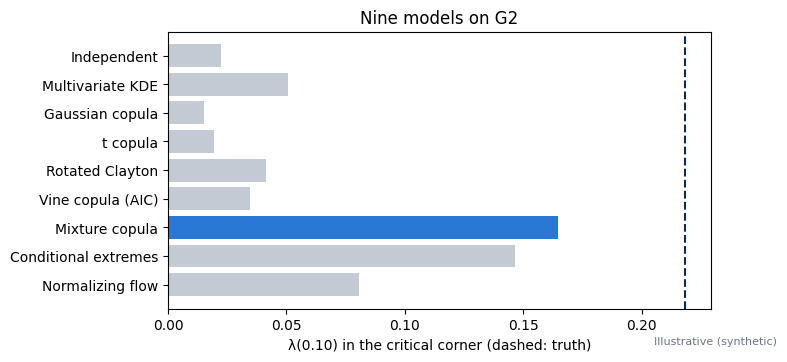

t copula: ν = 20; rotated Clayton: θ = 0.001; mixture weights [0.801 0.199]


In [7]:
FAMILY = {
    "Independent": lambda: Independent().fit(G2_tr),
    "Multivariate KDE": lambda: KDE().fit(G2_tr),
    "Gaussian copula": lambda: GaussianCopula().fit(G2_tr),
    "t copula": lambda: TCopula().fit(G2_tr),
    "Rotated Clayton": lambda: ClaytonPair().fit(G2_tr),
    "Vine copula (AIC)": lambda: Vine().fit(G2_tr),
    "Mixture copula": lambda: GMMScores().fit(G2_tr),
    "Conditional extremes": lambda: HT(0.90).fit(G2_tr),
    "Normalizing flow": lambda: Flow(2026, (4, 16, 1e-3)).fit(G2_tr),
}
fitted = {k: f() for k, f in FAMILY.items()}
samples = {k: m.sample(N_SAMPLES, seed=SAMPLE_SEED) for k, m in fitted.items()}
kept = {k: reject_invalid(S) for k, S in samples.items()}
loglik = {k: m.logpdf(G2_ho) for k, m in fitted.items()}
lams = {k: tail_dependence(kept[k][0], 0.10) for k in fitted}
shares = {k: float(critical(kept[k][0]).mean()) for k in fitted}

names = list(fitted)
fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(names))
ax.barh(y, [lams[k] for k in names], color=[BLUE if k == "Mixture copula" else GREY for k in names])
ax.axvline(TRUTH_LAM, color=INK, ls="--"); ax.set_yticks(y, names); ax.invert_yaxis()
ax.set(xlabel="λ(0.10) in the critical corner (dashed: truth)", title="Nine models on G2"); stamp(fig); plt.show()
print(f"t copula: ν = {fitted['t copula'].nu}; rotated Clayton: θ = {fitted['Rotated Clayton'].theta:.3f}; "
      f"mixture weights {np.round(fitted['Mixture copula'].g.weights_, 3)}")

**Try this.** Give the mixture three components instead of two.

In [8]:
k = 3   # try 1, 2, 3, 4
m = GMMScores().fit(G2_tr, k=k)
A, _ = reject_invalid(m.sample(N_SAMPLES, seed=SAMPLE_SEED))
print(f"k = {k}: held-out log-likelihood {m.logpdf(G2_ho).mean():.3f}, λ(0.10) {tail_dependence(A, 0.10):.3f}, critical share {critical(A).mean():.4f}")

k = 3: held-out log-likelihood -9.134, λ(0.10) 0.266, critical share 0.1097


## 3. Likelihood against λ

Held-out log-likelihood per event against tail dependence. Four models tie on likelihood while their λ differs by a factor of 9 to 11. Selection is blind in the same way: AIC above chose no vine pair with a tail in the corner, although rotated and two-parameter families were available.

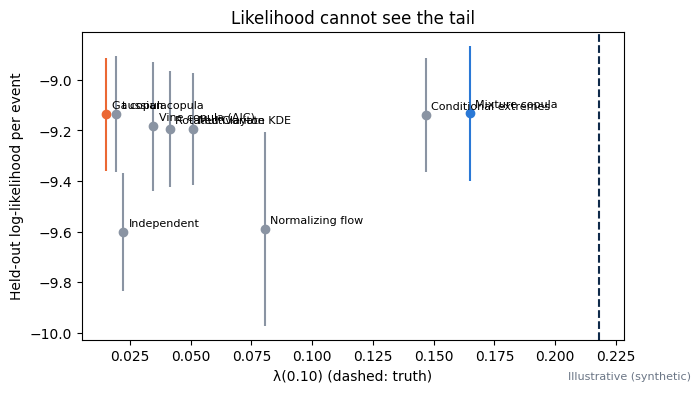

Independent            LL   -9.602  vs Gaussian copula -0.465 ± 0.061
Multivariate KDE       LL   -9.195  vs Gaussian copula -0.059 ± 0.047
Gaussian copula        LL   -9.136  vs Gaussian copula +0.000 ± 0.000
t copula               LL   -9.135  vs Gaussian copula +0.001 ± 0.012
Rotated Clayton        LL   -9.194  vs Gaussian copula -0.058 ± 0.021
Vine copula (AIC)      LL   -9.183  vs Gaussian copula -0.047 ± 0.033
Mixture copula         LL   -9.132  vs Gaussian copula +0.005 ± 0.048
Conditional extremes   LL   -9.139  vs Gaussian copula -0.003 ± 0.047
Normalizing flow       LL   -9.589  vs Gaussian copula -0.453 ± 0.132


In [9]:
ref = loglik["Gaussian copula"]
fig, ax = plt.subplots(figsize=(7, 4))
for k in names:
    se = loglik[k].std(ddof=1) / np.sqrt(len(ref))
    ax.errorbar(lams[k], loglik[k].mean(), yerr=1.96 * se, fmt="o", color=BLUE if k == "Mixture copula" else ORANGE if k == "Gaussian copula" else "#8a94a3")
    ax.annotate(k, (lams[k], loglik[k].mean()), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.axvline(TRUTH_LAM, color=INK, ls="--")
ax.set(xlabel="λ(0.10) (dashed: truth)", ylabel="Held-out log-likelihood per event", title="Likelihood cannot see the tail"); stamp(fig); plt.show()
for k in names:
    d = loglik[k] - ref
    print(f"{k:22s} LL {loglik[k].mean():8.3f}  vs Gaussian copula {d.mean():+.3f} ± {d.std(ddof=1) / np.sqrt(len(d)):.3f}")

**Try this.** Look further into the tail: use a stricter level.

In [10]:
q = 0.05   # try 0.02, 0.05, 0.20
print({k: round(tail_dependence(kept[k][0], q), 3) for k in names}, "truth", round(tail_dependence(truth, q), 3))

{'Independent': 0.0, 'Multivariate KDE': 0.004, 'Gaussian copula': 0.006, 't copula': 0.002, 'Rotated Clayton': 0.004, 'Vine copula (AIC)': 0.006, 'Mixture copula': 0.103, 'Conditional extremes': 0.043, 'Normalizing flow': 0.034} truth 0.074


## 4. The bulk-metric pitfall

A per-parameter distance can prefer the model that is further from the truth in the corner. Compare the Wasserstein distance of the gap with λ.

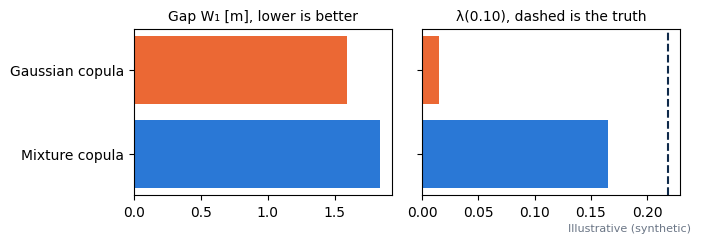

{'Gaussian copula': 1.59, 'Mixture copula': 1.83}


In [11]:
w1 = {k: float(stats.wasserstein_distance(G2_ho[:, 1], kept[k][0][:, 1])) for k in names}
pair = ["Gaussian copula", "Mixture copula"]
fig, axs = plt.subplots(1, 2, figsize=(7, 2.4))
axs[0].barh(pair, [w1[k] for k in pair], color=[ORANGE, BLUE]); axs[0].set_title("Gap W₁ [m], lower is better", fontsize=10); axs[0].invert_yaxis()
axs[1].barh(pair, [lams[k] for k in pair], color=[ORANGE, BLUE]); axs[1].axvline(TRUTH_LAM, color=INK, ls="--"); axs[1].set_title("λ(0.10), dashed is the truth", fontsize=10); axs[1].set_yticklabels([]); axs[1].invert_yaxis()
fig.tight_layout(); stamp(fig); plt.show()
print({k: round(w1[k], 2) for k in pair})

**Try this.** Use a different parameter: 0 ego speed, 1 gap, 2 Δv, 3 lateral speed.

In [12]:
j = 2   # try 0, 1, 2, 3
print({k: round(float(stats.wasserstein_distance(G2_ho[:, j], kept[k][0][:, j])), 3) for k in names})

{'Independent': 0.319, 'Multivariate KDE': 0.189, 'Gaussian copula': 0.29, 't copula': 0.29, 'Rotated Clayton': 0.298, 'Vine copula (AIC)': 0.279, 'Mixture copula': 0.437, 'Conditional extremes': 0.314, 'Normalizing flow': 0.511}


## 5. The λ test

Of the 160 held-out events, the 16 with the highest closing speed are the conditioning events, and 5 of those also fall in the lowest 10 % for time gap. If a model's λ were true, how likely is 5 or more of 16? An exact binomial answers it. Conditional extremes is shown at one pre-set threshold with 19 exceedances; across four thresholds its λ moves from 0.097 to 0.147 and three are rejected. The flow's size was chosen after a first setting's held-out result had been seen.

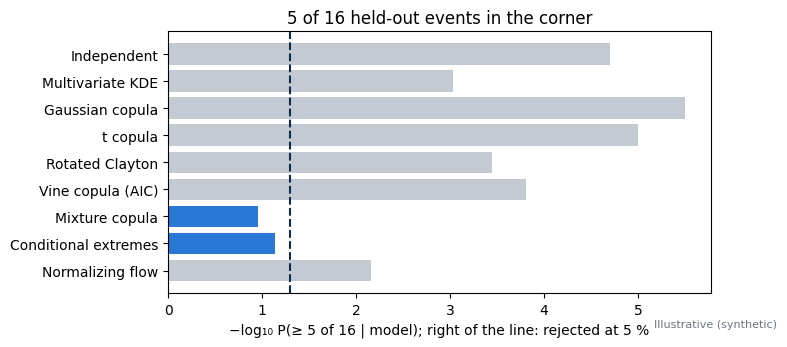

7 of 9 models rejected at 5 %
{'Independent': 1.98e-05, 'Multivariate KDE': 0.000924, 'Gaussian copula': 3.19e-06, 't copula': 1.01e-05, 'Rotated Clayton': 0.00036, 'Vine copula (AIC)': 0.000156, 'Mixture copula': 0.109, 'Conditional extremes': 0.073, 'Normalizing flow': 0.00696}


In [13]:
n_cond, hits = int(round(0.10 * N_HELD_OUT)), int(round(tail_dependence(G2_ho, 0.10) * round(0.10 * N_HELD_OUT)))
pvals = {k: float(stats.binom.sf(hits - 1, n_cond, lams[k])) for k in names}
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(names, [-np.log10(pvals[k]) for k in names], color=[BLUE if pvals[k] > 0.05 else GREY for k in names])
ax.axvline(-np.log10(0.05), color=INK, ls="--"); ax.invert_yaxis()
ax.set(xlabel="−log₁₀ P(≥ 5 of 16 | model); right of the line: rejected at 5 %", title=f"{hits} of {n_cond} held-out events in the corner"); stamp(fig); plt.show()
print(sum(p < 0.05 for p in pvals.values()), "of", len(pvals), "models rejected at 5 %")
print({k: float(f"{p:.3g}") for k, p in pvals.items()})

**Try this.** Ask what a smaller held-out set could have shown, keeping the same hit rate.

In [14]:
n = 8; h = 2   # conditioning events and hits; try (32, 10)
print({k: round(float(stats.binom.sf(h - 1, n, lams[k])), 4) for k in names})

{'Independent': 0.0128, 'Multivariate KDE': 0.059, 'Gaussian copula': 0.0062, 't copula': 0.0098, 'Rotated Clayton': 0.0406, 'Vine copula (AIC)': 0.0291, 'Mixture copula': 0.3895, 'Conditional extremes': 0.3323, 'Normalizing flow': 0.1313}


## 6. Critical share with intervals

The share check passes every model: all lie inside the held-out interval, including those below the truth.

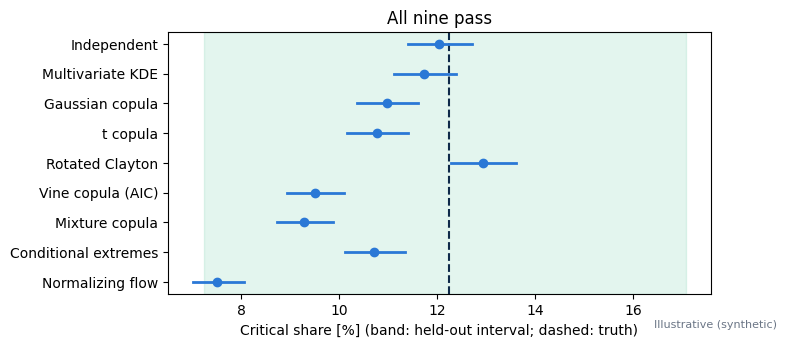

held-out 18/160 = 0.113 [0.072, 0.171]


In [15]:
k_ho = int(critical(G2_ho).sum())
lo_ho, hi_ho = wilson(k_ho, len(G2_ho))
ci = {k: wilson(int(critical(kept[k][0]).sum()), len(kept[k][0])) for k in names}
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.axvspan(100 * lo_ho, 100 * hi_ho, color="#1baf7a", alpha=0.12)
ax.axvline(100 * TRUTH_SHARE, color=INK, ls="--")
for i, k in enumerate(names):
    ax.plot([100 * ci[k][0], 100 * ci[k][1]], [i, i], color=BLUE, lw=2); ax.plot(100 * shares[k], i, "o", color=BLUE)
ax.set_yticks(range(len(names)), names); ax.invert_yaxis()
ax.set(xlabel="Critical share [%] (band: held-out interval; dashed: truth)", title="All nine pass"); stamp(fig); plt.show()
print(f"held-out {k_ho}/{len(G2_ho)} = {k_ho / len(G2_ho):.3f} [{lo_ho:.3f}, {hi_ho:.3f}]")

**Try this.** Move the definition of critical.

In [16]:
limit = 1.5   # seconds; try 1.0, 1.5, 3.0
print({k: round(float((derived(kept[k][0])["ttc_sw"] < limit).mean()), 4) for k in names}, "truth", round(float((derived(truth)["ttc_sw"] < limit).mean()), 4))

{'Independent': 0.0809, 'Multivariate KDE': 0.0768, 'Gaussian copula': 0.0687, 't copula': 0.0662, 'Rotated Clayton': 0.0859, 'Vine copula (AIC)': 0.0554, 'Mixture copula': 0.0602, 'Conditional extremes': 0.0707, 'Normalizing flow': 0.0419} truth 0.089


## 7. Power

The probability that a two-sided 5 % test of the critical share rejects each model at n = 160, and the events needed for 80 % power, by normal approximation.

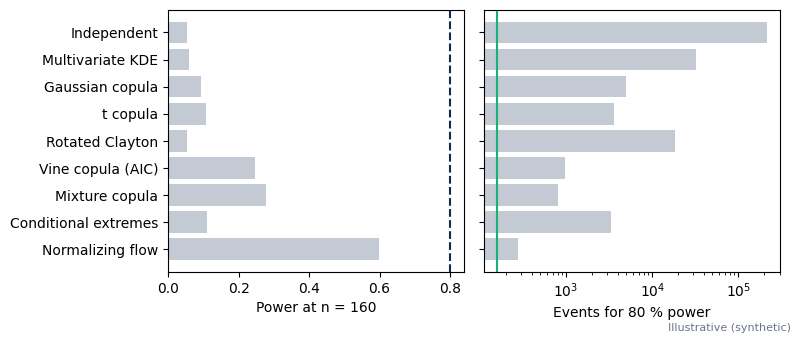

{'Independent': (0.052, 212063), 'Multivariate KDE': (0.059, 32460), 'Gaussian copula': (0.093, 4921), 't copula': (0.107, 3594), 'Rotated Clayton': (0.052, 18356), 'Vine copula (AIC)': (0.245, 965), 'Mixture copula': (0.279, 812), 'Conditional extremes': (0.111, 3321), 'Normalizing flow': (0.599, 281)}


In [17]:
ZA, ZB = stats.norm.ppf(0.975), stats.norm.ppf(0.80)


def power(p0, p1, n):
    s0, s1 = np.sqrt(p0 * (1 - p0) / n), np.sqrt(p1 * (1 - p1) / n)
    return float(stats.norm.sf((p0 + ZA * s0 - p1) / s1) + stats.norm.cdf((p0 - ZA * s0 - p1) / s1))


def n_for_80(p0, p1):
    return float(((ZA * np.sqrt(p0 * (1 - p0)) + ZB * np.sqrt(p1 * (1 - p1))) / (p1 - p0)) ** 2)


pw = {k: power(shares[k], TRUTH_SHARE, N_HELD_OUT) for k in names}
n80 = {k: n_for_80(shares[k], TRUTH_SHARE) for k in names}
fig, axs = plt.subplots(1, 2, figsize=(8, 3.4), sharey=True)
axs[0].barh(names, [pw[k] for k in names], color=GREY); axs[0].axvline(0.8, color=INK, ls="--"); axs[0].set_xlabel("Power at n = 160"); axs[0].invert_yaxis()
axs[1].barh(names, [n80[k] for k in names], color=GREY); axs[1].set_xscale("log"); axs[1].axvline(160, color="#1baf7a"); axs[1].set_xlabel("Events for 80 % power")
fig.tight_layout(); stamp(fig); plt.show()
print({k: (round(pw[k], 3), round(n80[k])) for k in names})

**Try this.** What would a larger validation set give?

In [18]:
n = 1000   # held-out events; try 400, 1000, 5000
print({k: round(power(shares[k], TRUTH_SHARE, n), 3) for k in names})

{'Independent': 0.056, 'Multivariate KDE': 0.083, 'Gaussian copula': 0.26, 't copula': 0.333, 'Rotated Clayton': 0.094, 'Vine copula (AIC)': 0.813, 'Mixture copula': 0.87, 'Conditional extremes': 0.355, 'Normalizing flow': 0.999}


## 8. Importance sampling

On G1, under the Gaussian copula, sample more often near the critical region and correct with a weight. The estimate is precise under the fitted model; that does not make the model right.

In [19]:
#| code-fold: true
def ttc_valid(X):
    """TTC at lane crossing for physically valid samples, inf for invalid ones (an invalid sample is no event)."""
    t = derived(X)["ttc_sw"].copy()
    t[~validity(X)["all"]] = np.inf
    return t


def ce_mean_shift(cop, ttc_max, n_pilot=2000, elite=0.1, seed=11):
    """One cross-entropy step in the copula's normal-score space: mean z of the pilot samples with the smallest
    TTC at lane crossing (the elite quantile, or all samples below ttc_max if there are more of them)."""
    Z = cop.sample_z(n_pilot, seed)
    t = ttc_valid(cop.from_z(Z))
    k = max(int(elite * n_pilot), int((t < ttc_max).sum()))
    return Z[np.argsort(t)[:k]].mean(0)


def is_estimate(cop, mu, ttc_max, n, seed):
    """Importance sampling of P(valid and TTC_sw < ttc_max) under the copula: proposal N(mu, R) in z-space,
    weight w = phi_R(z) / phi_R(z - mu) = exp(-mu' R^-1 z + mu' R^-1 mu / 2) (the marginal transforms cancel)."""
    Z = cop.sample_z(n, seed, mean=mu)
    a = cop.Ri @ mu
    w = np.exp(-Z @ a + 0.5 * mu @ a)
    hit = ttc_valid(cop.from_z(Z)) < ttc_max
    f = w * hit
    return dict(estimate=float(f.mean()), se=float(f.std(ddof=1) / np.sqrt(n)), ess=float(w.sum() ** 2 / (w ** 2).sum()),
                ess_hits=float(f.sum() ** 2 / (f ** 2).sum()) if hit.any() else 0.0, hit_share=float(hit.mean()),
                w_mean=float(w.mean()), w_min=float(w.min()), w_median=float(np.median(w)), w_max=float(w.max()),
                w_hits_median=float(np.median(w[hit])) if hit.any() else None), Z, w, hit


def crude_estimate(cop, ttc_max, n, seed):
    hit = ttc_valid(cop.sample(n, seed)) < ttc_max
    p = float(hit.mean())
    return dict(estimate=p, se=float(np.sqrt(max(p * (1 - p), 1e-300) / n)), hits=int(hit.sum()))

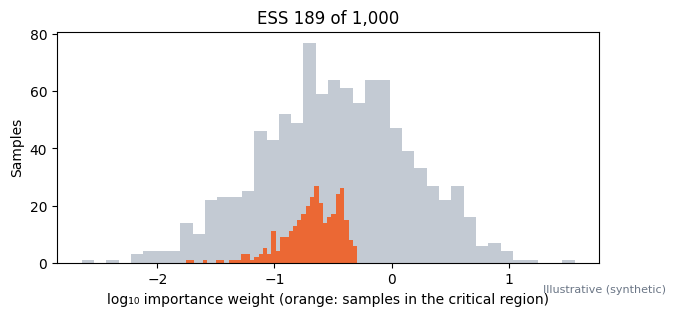

reference 0.07946; plain 0.08600 ± 0.00887; importance sampling 0.07946 ± 0.00408
variance reduction ×4.7; 33.4% of samples hit the region


In [20]:
cop = GaussianCopula().fit(G1_tr)
mu = ce_mean_shift(cop, 2.0)
ref = crude_estimate(cop, 2.0, 1_000_000, seed=99)
crude = crude_estimate(cop, 2.0, 1000, seed=21)
isr, Z, w, hit = is_estimate(cop, mu, 2.0, 1000, seed=21)
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log10(w), bins=40, color=GREY); ax.hist(np.log10(w[hit]), bins=40, color=ORANGE)
ax.set(xlabel="log₁₀ importance weight (orange: samples in the critical region)", ylabel="Samples", title=f"ESS {isr['ess']:.0f} of 1,000"); stamp(fig); plt.show()
print(f"reference {ref['estimate']:.5f}; plain {crude['estimate']:.5f} ± {crude['se']:.5f}; importance sampling {isr['estimate']:.5f} ± {isr['se']:.5f}")
print(f"variance reduction ×{(crude['se'] / isr['se']) ** 2:.1f}; {isr['hit_share']:.1%} of samples hit the region")

**Try this.** Make the target rarer.

In [21]:
limit = 1.0   # seconds; try 0.5, 1.0, 1.5
mu_t = ce_mean_shift(cop, limit)
r, *_ = is_estimate(cop, mu_t, limit, 1000, seed=21)
c_t = crude_estimate(cop, limit, 1000, seed=21)
print(f"target {limit} s: importance sampling {r['estimate']:.5f} ± {r['se']:.5f}, plain {c_t['estimate']:.5f} ± {c_t['se']:.5f}, ESS {r['ess']:.0f}")

target 1.0 s: importance sampling 0.02116 ± 0.00183, plain 0.02000 ± 0.00443, ESS 189


## Summary of the numbers

The test in `tests/test_tail_notebook.py` compares these with the published evidence.

In [22]:
for k in names:
    d = loglik[k] - loglik["Gaussian copula"]
    results[k] = dict(loglik=float(loglik[k].mean()), paired_vs_gaussian=float(d.mean()), **{"lambda": lams[k]}, critical_share=shares[k],
                      kept=kept[k][1], p_lambda=pvals[k], power=pw[k], n_for_80=n80[k])
results["importance_sampling"] = dict(estimate=isr["estimate"], se=isr["se"], ess=isr["ess"], reference=ref["estimate"], crude=crude["estimate"])
results["runtime_s"] = time.time() - T0
if os.environ.get("TAIL_RESULTS_JSON"):
    json.dump(results, open(os.environ["TAIL_RESULTS_JSON"], "w"), indent=1)
print(f"Finished in {results['runtime_s']:.0f} s")

Finished in 13 s
